# Distributed Text Classification of Irish Event Listings Using TF-IDF and a Multilayer Perceptron in PySpark

This paper presents an end-to-end text classification pipeline for Irish event listings built on the Hadoop Distributed File System (HDFS), Apache Spark and its machine learning library, MLlib. Event descriptions were cleaned, converted into term frequency-inverse document frequency (TF-IDF) features and classified them.

### Video Recording links

- Link 1: https://drive.google.com/file/d/14oolR9qhjVZuUwFVXxX3DvaakYOnqO88/view?usp=sharing
- Link 2: https://drive.google.com/file/d/1XZE0s0-yVHN09Q7k2mXKRZMCwao888nR/view?usp=sharing

I uploaded the practical demonstration video 

Dataset Link:
 https://data.gov.ie/dataset/events

## Import Libraries

Necessary libraries are imported.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql.functions import size, split
from pyspark.ml.feature import Tokenizer, StopWordsRemover, CountVectorizer, StringIndexer, HashingTF, IDF
from pyspark.ml.classification import MultilayerPerceptronClassifier, MultilayerPerceptronClassificationModel
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.mllib.evaluation import MulticlassMetrics
import pandas as pd


In [2]:
import os
import sys
from pyspark.sql import SparkSession

# Ensure PySpark uses the correct Python interpreter
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Initialize SparkSession
spark = SparkSession.builder \
    .appName("CA1_Spark_Environment_Check") \
    .getOrCreate()

# Quick distributed job to verify Spark functionality
test_df = spark.range(100)
print("Spark environment OK — Distributed count result:", test_df.count())


26/10/16 22:21:30 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


Spark environment OK — Distributed count result: 100


## Initialize Spark Session

In [3]:
spark = SparkSession.builder.appName("Events_Classification").getOrCreate()


26/10/16 22:21:33 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


## Load the Dataset from HDSF

Now that Spark is working. The dataset had been load directly from HDFS under hduser.


In [4]:
from pyspark.sql import functions as F

# The dataset was uploaded to HDFS under the directory /user/hduser/CA1_Semester2_MisselGarcia. The file Events.csv is stored in HDFS and accessed by PySpark using the distributed file system. 

df = spark.read.csv(
    "hdfs:///user/hduser/CA1_Semester2_MisselGarcia/Events.csv",
    header=True,
    inferSchema=True,
    multiLine=True,
    escape="\"",
    quote="\"",
    ignoreLeadingWhiteSpace=True,
    ignoreTrailingWhiteSpace=True,
    mode="PERMISSIVE"
)


print(f"Total rows: {df.count()}")
print(f"Total columns: {len(df.columns)}")

Total rows: 4038
Total columns: 20


In [5]:
df.printSchema()

root
 |-- Name: string (nullable = true)
 |-- Event Type: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Image: string (nullable = true)
 |-- Contact URL: string (nullable = true)
 |-- Booking URL: string (nullable = true)
 |-- Contact Phone Number: long (nullable = true)
 |-- Booking Phone Number: long (nullable = true)
 |-- Venue Name: string (nullable = true)
 |-- Address: string (nullable = true)
 |-- County: string (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- Is Free To Visit: string (nullable = true)
 |-- Price: string (nullable = true)
 |-- Start Date: string (nullable = true)
 |-- End Date: string (nullable = true)
 |-- Start Time: timestamp (nullable = true)
 |-- End Time: timestamp (nullable = true)
 |-- Recurring Dates: string (nullable = true)



In [6]:
df.dtypes

[('Name', 'string'),
 ('Event Type', 'string'),
 ('Description', 'string'),
 ('Image', 'string'),
 ('Contact URL', 'string'),
 ('Booking URL', 'string'),
 ('Contact Phone Number', 'bigint'),
 ('Booking Phone Number', 'bigint'),
 ('Venue Name', 'string'),
 ('Address', 'string'),
 ('County', 'string'),
 ('Latitude', 'double'),
 ('Longitude', 'double'),
 ('Is Free To Visit', 'string'),
 ('Price', 'string'),
 ('Start Date', 'string'),
 ('End Date', 'string'),
 ('Start Time', 'timestamp'),
 ('End Time', 'timestamp'),
 ('Recurring Dates', 'string')]

In [7]:
from pyspark.sql import functions as F

# Keeping Description and Event Type for the study
df_filtered = df.select(
    F.col("Description").alias("description"),
    F.col("Event Type").alias("event_type")
)

# Checking the updated schema
df_filtered.printSchema()

# Inspecting the first few rows
df_filtered.show(2, truncate=False)

root
 |-- description: string (nullable = true)
 |-- event_type: string (nullable = true)

+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------+
|description                                                                                                                                                                                                  

In [8]:
print("NULL values in description:",
      df.filter(df["description"].isNull()).count())

print("NULL values in event type:",
      df.filter(df["event type"].isNull()).count())

NULL values in description: 0
NULL values in event type: 0


In [9]:
df = df.select("Description", "Event Type")

## Data Processing

### Exploratory Data Analysis

#### Check Schema

In [10]:
df.printSchema()

root
 |-- Description: string (nullable = true)
 |-- Event Type: string (nullable = true)



#### Data types

In [11]:
df.dtypes

[('Description', 'string'), ('Event Type', 'string')]

#### Summary Statistics

In [12]:
df.describe().show()

+-------+--------------------+----------+
|summary|         Description|Event Type|
+-------+--------------------+----------+
|  count|                4038|      4038|
|   mean|                NULL|      NULL|
| stddev|                NULL|      NULL|
|    min|\nEnter the world...|     Event|
|    max|📅 Wednesday, 21s...|    Market|
+-------+--------------------+----------+



#### Analyzing for Missing Values

In [13]:
df.filter(df["Event Type"].isNull()).show()
df.filter(df["Description"].isNull()).show()

+-----------+----------+
|Description|Event Type|
+-----------+----------+
+-----------+----------+

+-----------+----------+
|Description|Event Type|
+-----------+----------+
+-----------+----------+



No missing values have found.

#### Count Unique Values

This shows the categories 

In [14]:
df.select("Description").distinct().show()


+--------------------+
|         Description|
+--------------------+
|As if three night...|
|The album is cine...|
|Visit Dullahan to...|
|Along the way, di...|
|Every element of ...|
|Visit Stillgarden...|
|Kenmare's Samhain...|
|Get ready for a s...|
|Everyone nowadays...|
|Set against the d...|
|Teidí Tours retur...|
|Learn all about t...|
|Step into the mag...|
|Atlantic Breath: ...|
|Celebrate Samhain...|
|Gareth brings the...|
|All his mates are...|
|Date: Monday, 12 ...|
|From the theatric...|
|You can make it H...|
+--------------------+
only showing top 20 rows


##### Value Count for Categorical Variables

In [15]:
df.groupBy("Event type").count().orderBy("count", ascending=False).show()


+----------+-----+
|Event type|count|
+----------+-----+
|     Event| 3574|
|  Festival|  461|
|    Market|    3|
+----------+-----+



#### Text length distribution
It is possible to identify extremely short descriptions that may not contain enough semantic information

In [16]:
df = df.withColumn("text_len", F.length(F.col("Description")))

df.select(
    F.mean("text_len").alias("avg_length"),
    F.min("text_len").alias("min_length"),
    F.max("text_len").alias("max_length")
).show()


+-----------------+----------+----------+
|       avg_length|min_length|max_length|
+-----------------+----------+----------+
|664.3662704309064|       198|       839|
+-----------------+----------+----------+



In [17]:
df.groupBy("Description").count().filter(F.col("count") > 1).show()


+--------------------+-----+
|         Description|count|
+--------------------+-----+
|As if three night...|    2|
|The album is cine...|    5|
|Visit Stillgarden...|   38|
|Kenmare's Samhain...|    2|
|Teidí Tours retur...|    9|
|Learn all about t...|    4|
|Celebrate Samhain...|    3|
|From the theatric...|    2|
|Celebrate the tra...|    2|
|Come and sip on a...|    7|
|This autumn, the ...|    3|
|Attractions inclu...|   21|
|No experience? No...|   32|
|Celebrate Samhain...|    4|
|This festival bri...|    2|
|From the seductiv...|    6|
|West Cork Music p...|    3|
|Join us this Octo...|   14|
|Step into the gri...|    2|
|The event include...|    9|
+--------------------+-----+
only showing top 20 rows


In [18]:
df.select("Description").show(20, truncate=False)


+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|Description                                                                                                                                                                                                                                                                                                        

### Text cleaning (Spark)
Reducing noise for the model training before applying NLP techniques, first cleaning the Description column. following to remove URLs, then lowercase, then remove special characters, all of this to avoid introducing noise into the tokenisation and TF-IDF stages.


In [19]:
from pyspark.sql.functions import regexp_replace, col, lower, trim

# 1. Remove URLs
df = df.withColumn(
    "Description",
    regexp_replace(col("Description"), "http\\S+", "")
)

# 2. Lowercase the text to ensure consistency
df = df.withColumn(
    "Description",
    lower(col("Description"))
)

# 3. Remove special characters while keeping letters, numbers, accents and spaces
df = df.withColumn(
    "Description",
    regexp_replace(col("Description"), "[^a-z0-9áéíóúüñ ]", "")
)

# 4. Replace multiple spaces with a single space
df = df.withColumn(
    "Description",
    regexp_replace(col("Description"), "\\s+", " ")
)

# 5. Trim leading/trailing spaces
df = df.withColumn("Description", trim(col("Description")))

# 6. Remove rows where the description becomes empty after cleaning
df = df.filter(col("Description") != "")

print("Rows after cleaning:", df.count())



Rows after cleaning: 4038


In [20]:
df.select("Description").show(20, truncate=False)


+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|Description                                                                                                                                                                                                                                                                                                                                                                 

In [21]:
df = df.dropDuplicates(["Description"])

In [22]:
df.select("Description").show(5, truncate=False)

+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|Description                                                                                                                                                                                                                                                                                                                                   

In [23]:
df.groupBy("Event Type").count().orderBy("count", ascending=False).show()

+----------+-----+
|Event Type|count|
+----------+-----+
|     Event|  678|
|  Festival|   97|
|    Market|    3|
+----------+-----+



## Data Visualization

Distributions of the dataset were plotted 

#### Distribution of Event Types by Category

Convert Spark DataFrame to Pandas for visualization since  Spark does not support direct plotting, so it was necessary to convert to Pandas and see how to use Matplotlib for visual analysis of class distribution.

In [24]:
event_counts = df.groupBy("Event Type").count().orderBy("count", ascending=False)
event_counts_pd = event_counts.toPandas()

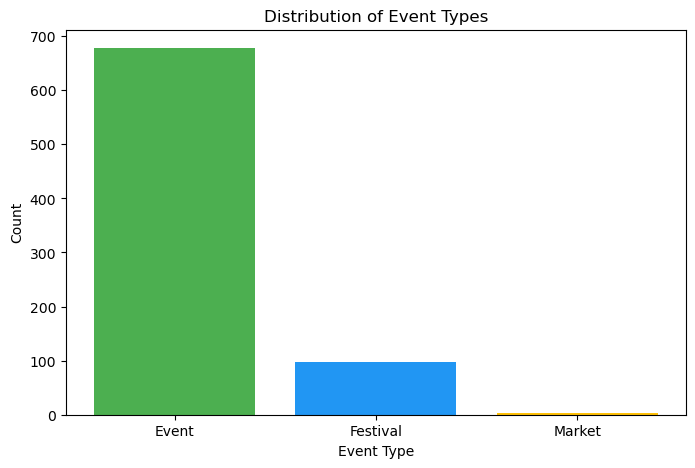

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(event_counts_pd["Event Type"], event_counts_pd["count"], 
        color=["#4CAF50", "#2196F3", "#FFC107"])
plt.title("Distribution of Event Types")
plt.xlabel("Event Type")
plt.ylabel("Count")
plt.show()

This bar chart illustrates the frequency of each event category.
Understanding class imbalance is essential before training a classifier.

#### Distribution by Words or Text Length

In [26]:
# Calculate the word count for each Type Event
df_word = df.withColumn("word_count", size(split(df["Description"], " ")))

# Show a preview
df_word.select("Description", "word_count").show(5)

+--------------------+----------+
|         Description|word_count|
+--------------------+----------+
|get ready for a f...|        96|
|step into a seaso...|        92|
|having a laugh de...|        69|
|it is an apt time...|       126|
|along the way dis...|        31|
+--------------------+----------+
only showing top 5 rows


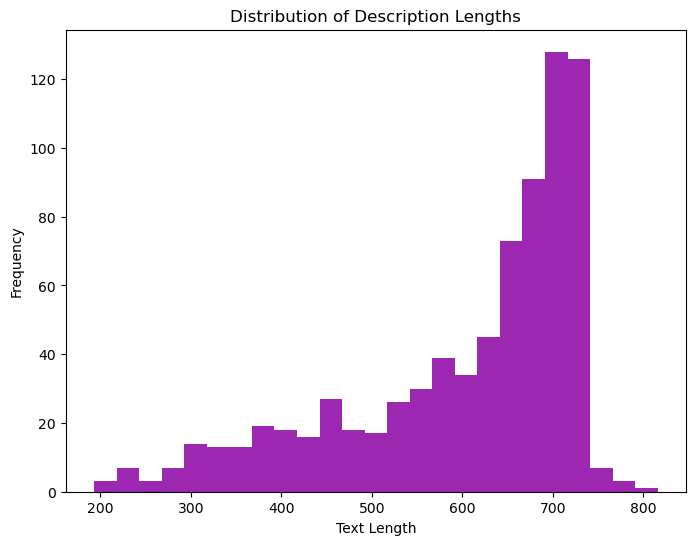

In [27]:
# Text length helps identify whether descriptions contain enough semantic information for TF-IDF vectorization.
from pyspark.sql.functions import length, col


df = df.withColumn("text_len", length(col("Description")))
text_len_pd = df.select("text_len").toPandas()

plt.figure(figsize=(8,6))
plt.hist(text_len_pd["text_len"], bins=25, color="#9C27B0")
plt.title("Distribution of Description Lengths")
plt.xlabel("Text Length")
plt.ylabel("Frequency")
plt.show()





#### Boxplot

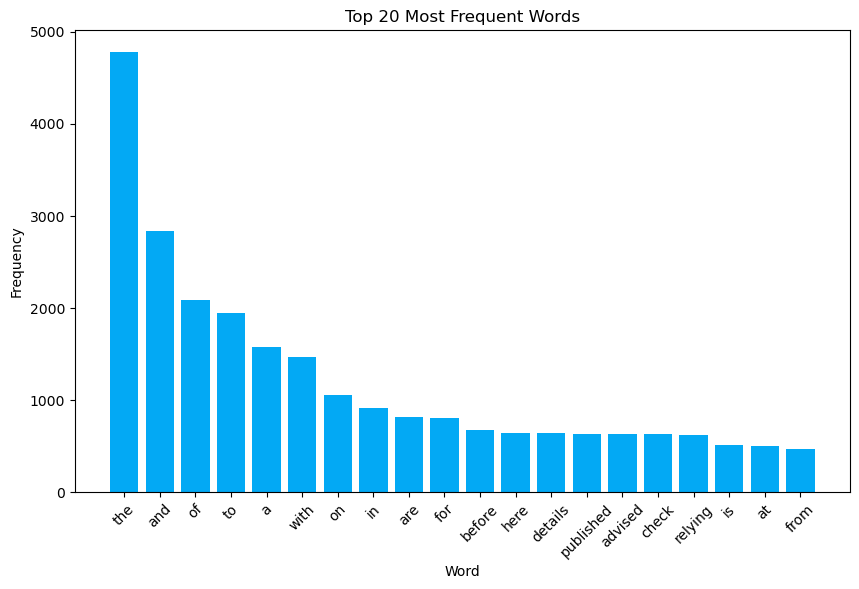

In [28]:
from pyspark.ml.feature import Tokenizer
tokenizer = Tokenizer(inputCol="Description", outputCol="tokens")
df_tokens = tokenizer.transform(df)

tokens_pd = df_tokens.select("tokens").toPandas()

from collections import Counter

# All tokens into a single list enables frequency analysis.
all_words = []
for row in tokens_pd["tokens"]:
    all_words.extend(row)

word_freq = Counter(all_words)
common_words = word_freq.most_common(20)
words, counts = zip(*common_words)

plt.figure(figsize=(10,6))
plt.bar(words, counts, color="#03A9F4")
plt.xticks(rotation=45)
plt.title("Top 20 Most Frequent Words")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.show()

In [29]:

from pyspark.sql.functions import size, split, col

# Word count provides insight into the complexity and richness of each event description.
# This helps justify the use of TF-IDF and informs model selection.

df_word = df.withColumn("word_count", size(split(col("Description"), " ")))

# Preview
df_word.select("Description", "word_count").show(5, truncate=80)



+--------------------------------------------------------------------------------+----------+
|                                                                     Description|word_count|
+--------------------------------------------------------------------------------+----------+
|get ready for a fantastic night of live entertainment with gearoid mccarthy a...|        96|
|step into a season of ancient folklore haunting tales music and mystery where...|        92|
|having a laugh despite the gloom kilkenomics uniquely brings together some of...|        69|
|it is an apt time at the threshold of the turning of the wheel of the year to...|       126|
|along the way discover some of the customs and traditions associated with sam...|        31|
+--------------------------------------------------------------------------------+----------+
only showing top 5 rows


## Text Transformation and Feature Engineering

#### Tokenization
Converting the text into smaller units, known as tokens. This facilitates machines understanding and processing.

In [30]:
# Tokenizing
tokenizer = Tokenizer(inputCol="Description", outputCol="words")
df_words = tokenizer.transform(df)

### Stop-Word Removal
stop words are filtered out from input text data, removing commonly used used words that do not carry significant meaning.

In [31]:
# Remove Stopwords
remover = StopWordsRemover(inputCol="words", outputCol="filtered_words")
df_filtered = remover.transform(df_words)


### Word Vectorization
Tokens were converted into numerical vector using Term Frequency-Inverse Document, capturing word importance within the corpus.

In [32]:
# Convert words into numeric features using HashingTF (TF)
hashingTF = HashingTF(inputCol="filtered_words", outputCol="rawFeatures", numFeatures=500)
df_hashed = hashingTF.transform(df_filtered)

In [33]:
# Compute TF-IDF
idf = IDF(inputCol="rawFeatures", outputCol="features")
idf_model = idf.fit(df_hashed)
df_transformed = idf_model.transform(df_hashed)

### Label Encoding
Categorical labels were converted into numerical format.

In [34]:
# Convert category labels to numerical values using StringIndexer
indexer = StringIndexer(inputCol="Event Type", outputCol="label")
df_final = indexer.fit(df_transformed).transform(df_transformed)

In [35]:
# Show final dataset with features
df_final.select("Event Type", "label").show(5, truncate=False)


+----------+-----+
|Event Type|label|
+----------+-----+
|Event     |0.0  |
|Festival  |1.0  |
|Event     |0.0  |
|Event     |0.0  |
|Event     |0.0  |
+----------+-----+
only showing top 5 rows


## Model Training and Evaluation

For this proyect the Multilayer Perceptron Classifier from Spark MLlib is used.
MLP is a type of artificial neural network consisting of multiple layers of neurons. The neurons in the MLP typically use nonlinear activation functions, allowing the network to learn complex patterns in data. 

### Data Splitting
the dataset was partitioned into 80% for training and 20% for testing.

In [36]:
# Split data into training and testing sets (80% train, 20% test)
train_data, test_data = df_final.randomSplit([0.8, 0.2], seed=42)

### Model Definition
the MLP model is configured with 500 neurons in the firs hidden layer, 150 neurons in the second hidden layer and 32 neurons in the third hidden layer.

In [41]:
# Define MLP model layers
layers = [500, 150, 32, len(df_final.select("Event Type").distinct().collect())] 


In [42]:
# Initialize MLP Classifier
mlp = MultilayerPerceptronClassifier(featuresCol="features", labelCol="label", layers=layers, maxIter=100)


### Train the model
The model was trained on the training dataset, optimizing parameters to minimize classification error.

In [43]:
# Train the model
mlp_model = mlp.fit(train_data)

This model is been saved in Hadoop 

## Making Predictions
The trained MLP model was tested in making predictions on the test dataset.

In [44]:
# Make predictions
predictions = mlp_model.transform(test_data)

In [45]:
# Show predictions on test data
predictions.select("Description", "Event Type", "prediction").show(5, truncate=False)


+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------+----------+
|Description                                                                                                                                                                                                                                                          

## Accuracy
the model was evaluated by MulticlassClassificationEvaluator, achieving an accuracy of 89%.

The MulticlassClassificationEvaluator in PySpark is a utility for assessing the performance of multiclass classification models. It computes various evaluation metrics, such as accuracy, F1 score, and log loss, to gauge model effectiveness

In [46]:
# Make predictions
predictions = mlp_model.transform(test_data)


# Evaluate the model (accuracy)
evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
accuracy = evaluator.evaluate(predictions)

print(f"Test Accuracy: {accuracy:.2f}")


Test Accuracy: 0.89


### Screenshot of Hadoop

We can observe that the trained model is been saved in HDFS

In [47]:
mlp_model.write().overwrite().save("hdfs:///user/hduser/CA1_Semester2_MisselGarcia/mlp_model")

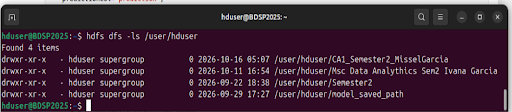

## Model Evaluation

Training the model I got the result with 89% of accuaracy, indicating that the classifier correctly predicts the majority of event categories.  
To provide a more complete assessment of the model’s performance, additional metrics such as F1-score, precision, and recall were calculated as well as additional task.

In [48]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# F1 Score
evaluator_f1 = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
)
f1 = evaluator_f1.evaluate(predictions)
print(f"F1 Score: {f1:.2f}")

# Precision
evaluator_precision = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedPrecision"
)
precision = evaluator_precision.evaluate(predictions)
print(f"Precision: {precision:.2f}")

# Recall
evaluator_recall = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedRecall"
)
recall = evaluator_recall.evaluate(predictions)
print(f"Recall: {recall:.2f}")


F1 Score: 0.89


Precision: 0.90


Recall: 0.89


### New Type of Events Prediction
To demonstrate the practical use of the trained model, a new event description was processed.

In [49]:
predictions.groupBy("label", "prediction").count().orderBy("label", "prediction").show()

+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  0.0|       0.0|  106|
|  0.0|       1.0|    4|
|  0.0|       2.0|    3|
|  1.0|       0.0|    6|
|  1.0|       1.0|    4|
|  2.0|       0.0|    1|
+-----+----------+-----+



In [50]:
from pyspark.sql import functions as F
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Class names from the data (label -> Event Type)
label_names = {row["label"]: row["Event Type"]
               for row in predictions.select("label", "Event Type").distinct().collect()}

# Baseline: majority class share in test
n_test = predictions.count()
majority = predictions.groupBy("label").count().orderBy(F.desc("count")).first()
print(f"Test: {n_test} rows | Baseline ({label_names[majority['label']]}): {majority['count'] / n_test:.4f}")

ev = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")
print(f"Accuracy: {ev.evaluate(predictions, {ev.metricName: 'accuracy'}):.4f}")

# Per-class metrics
for lbl in sorted(label_names):
    p = ev.evaluate(predictions, {ev.metricName: "precisionByLabel", ev.metricLabel: lbl})
    r = ev.evaluate(predictions, {ev.metricName: "recallByLabel", ev.metricLabel: lbl})
    f = ev.evaluate(predictions, {ev.metricName: "fMeasureByLabel", ev.metricLabel: lbl})
    n = predictions.filter(F.col("label") == lbl).count()
    print(f"{label_names[lbl]:10s} P={p:.3f} R={r:.3f} F1={f:.3f} n={n}")



Test: 124 rows | Baseline (Event): 0.9113


Accuracy: 0.8871


Event      P=0.938 R=0.938 F1=0.938 n=113


Festival   P=0.500 R=0.400 F1=0.444 n=10


Market     P=0.000 R=0.000 F1=0.000 n=1


## Conclusion:

I implemented a complete distributed workflow with HDFS and PySpark reading the CSV from HDFS, cleaning and deduplicating the text (4,038 → 778 rows), tokenization, stop-word removal, TF-IDF, label encoding, and training a Multilayer Perceptron with MLlib. The trained model was saved back to HDFS.

The model reached an accuracy of 0.887, but this is below the majority-class baseline of 0.911 (always predicting "Event"). The per-class results show the real problem: the model found only 4 of the 10 Festival cases (recall 0.40, F1 0.44) and missed the only Market case.

The main reasons are class imbalance, a large network for a small training set (654 rows), and a small data leakage, because IDF and StringIndexer were fitted before the train/test split. In future work, I would fit all steps only on the training data, use a stratified split, oversample the Festival class, and test the pipeline on a larger cluster.

